# Шаг 1. Загрузка и очистка данных

**Проект:** отмены бронирований в отелях — прогноз и политика предоплаты.

**Цель шага:** получить очищенный датасет, в котором каждое решение по очистке посчитано и обосновано.

**Содержание:** 1. Загрузка · 2. Первичная проверка · 3. Проблемы и решения · 4. Дубли · 5. Запуск очистки и журнал · 6. Устойчивость к обработке дублей · 7. Признаки · 8. Гарантии · 9. Выводы

In [1]:
import pandas as pd
from IPython.display import Image

from src.data import load_raw
from src.features import LEAKAGE_COLUMNS
from src.pipeline import build_dataset, check_guarantees, compare_variants, save_outputs
from src.plots import FIGURES_DIR

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', None)

## 1. Загрузка

Датасет Hotel Booking Demand (Antonio, Almeida, Nunes, *Data in Brief*, 2019): брони двух отелей в Португалии — городского (Лиссабон) и курортного (Алгарви), заезды 07.2015–08.2017. По документации датасета одна строка — одна бронь; в §4 показываем, что одинаковые строки, скорее всего, — номера одной групповой брони.

**Что делаем.** Загружаем исходный файл с помощью функции `load_raw` и смотрим, сколько в нём строк и колонок. Это отправная точка: все дальнейшие числа в тетради считаются от неё.

In [2]:
raw = load_raw()
raw.shape

(119390, 32)

Ячейка загрузила таблицу: 119 390 строк (броней) и 32 колонки.

**Вывод.** Данные загружены без потерь: 119 390 строк и 32 колонки. Дальше проверяем, в каком они состоянии.

## 2. Первичная проверка

Типы, пропуски и число уникальных значений по каждой колонке.

**Что делаем.** Прежде чем что-то чистить, смотрим на данные целиком: какой тип у каждой колонки, где есть пропуски, сколько разных значений. Так мы заранее видим, где искать проблемы, и заодно разбираем роль каждой колонки: цель, признак или «утечка».

In [3]:
DESCRIPTIONS = {
    'hotel': 'тип отеля: City Hotel или Resort Hotel',
    'is_canceled': 'бронь отменена (1) или нет (0) — целевая переменная',
    'lead_time': 'дней между датой бронирования и датой заезда',
    'arrival_date_year': 'год заезда',
    'arrival_date_month': 'месяц заезда (название)',
    'arrival_date_week_number': 'номер недели заезда (расходится с датой, см. §3.6)',
    'arrival_date_day_of_month': 'день месяца заезда',
    'stays_in_weekend_nights': 'число ночей в выходные дни',
    'stays_in_week_nights': 'число ночей в будние дни',
    'adults': 'число взрослых гостей',
    'children': 'число детей',
    'babies': 'число младенцев',
    'meal': 'тип забронированного пакета питания',
    'country': 'страна происхождения гостя (код)',
    'market_segment': 'сегмент продаж — группа клиентов, канал привлечения',
    'distribution_channel': 'канал продаж брони',
    'is_repeated_guest': 'гость уже бронировал раньше (1) или нет (0)',
    'previous_cancellations': 'число прошлых отмен этого гостя',
    'previous_bookings_not_canceled': 'число прошлых неотменённых броней гостя',
    'reserved_room_type': 'забронированный тип номера',
    'assigned_room_type': 'фактически присвоенный тип номера — известен при заезде',
    'booking_changes': 'число изменений брони после создания — известно постфактум',
    'deposit_type': 'тип депозита: без возврата, с возвратом, нет депозита',
    'agent': 'ID турагента (анонимный код)',
    'company': 'ID компании-заказчика (анонимный код)',
    'days_in_waiting_list': 'дней в листе ожидания до подтверждения',
    'customer_type': 'тип клиента: транзиент, группа, контракт и т. п.',
    'adr': 'средняя цена за номер за ночь, €',
    'required_car_parking_spaces': 'число нужных парковочных мест',
    'total_of_special_requests': 'число специальных пожеланий',
    'reservation_status': 'финальный статус брони — известен только по итогу',
    'reservation_status_date': 'дата финального статуса — известна только по итогу',
}


def _role(column):
    """Роль колонки: цель, утечка (LEAKAGE_COLUMNS), удаляется на шаге 11 или признак."""
    if column == 'is_canceled':
        return 'цель'
    if column in LEAKAGE_COLUMNS:
        return 'утечка'
    if column == 'arrival_date_week_number':
        return 'удаляется'
    return 'признак'


overview = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'пропусков': raw.isna().sum(),
    'уникальных': raw.nunique(),
    'роль': [_role(col) for col in raw.columns],
    'описание': [DESCRIPTIONS[col] for col in raw.columns],
})
overview

,тип,пропусков,уникальных,роль,описание
hotel,str,0,2,признак,тип отеля: City Hotel или Resort Hotel
is_canceled,int64,0,2,цель,бронь отменена (1) или нет (0) — целевая переменная
lead_time,int64,0,479,признак,дней между датой бронирования и датой заезда
arrival_date_year,int64,0,3,признак,год заезда
arrival_date_month,str,0,12,признак,месяц заезда (название)
arrival_date_week_number,int64,0,53,удаляется,"номер недели заезда (расходится с датой, см. §3.6)"
arrival_date_day_of_month,int64,0,31,признак,день месяца заезда
stays_in_weekend_nights,int64,0,17,признак,число ночей в выходные дни
stays_in_week_nights,int64,0,35,признак,число ночей в будние дни
adults,int64,0,14,признак,число взрослых гостей


Таблица показывает по каждой из 32 колонок тип, число пропусков, число уникальных значений, роль и описание. Пропуски есть только в четырёх колонках: `children` (4), `country` (488), `agent` (16 340) и `company` (112 593).

**Роли переменных.**

- **Цель** — `is_canceled`.
- **Признаки брони:** отель, срок брони (`lead_time`), дата заезда, ночи, гости, питание, страна, сегмент и канал продаж, история гостя, тип номера, депозит, агент, компания, лист ожидания, тип клиента, цена за ночь (`adr`), парковка, спецзапросы.
- **Утечки** — колонки, значения которых известны только после брони или в день заезда; в модель они не попадут:

In [4]:
list(LEAKAGE_COLUMNS)

['reservation_status',
 'reservation_status_date',
 'assigned_room_type',
 'booking_changes']

Это четыре колонки-«утечки»: итог брони, дата итога, фактически выданный номер и число изменений брони. Их значения становятся известны уже после брони или в день заезда, поэтому для прогноза на момент бронирования использовать их нельзя.

In [5]:
int(raw.duplicated().sum())

31994

Ячейка посчитала полностью одинаковые строки: таких копий 31 994. Это почти четверть таблицы, поэтому им отдан отдельный раздел 4.

**Вывод.** Пропуски — в `children`, `country`, `agent`, `company`; есть полностью одинаковые строки. Ниже — каждая проблема отдельно: что нашли, решение, почему.

## 3. Проблемы и решения

**Что делаем.** Разбираем шесть типов проблем в данных: ошибки в цене, нереальное число гостей, брони без ночей и без гостей, категории `Undefined`, пропуски и неверный номер недели. Для каждой показываем доказательство в числах, принимаем решение и объясняем, почему оно именно такое. Каждое решение потом превращается в шаг очистки с номером (раздел 5).

### 3.1. Ошибки в цене за ночь

**Что проверяем.** Цена за ночь (`adr`) должна быть положительной и правдоподобной. Ищем значения, которые явно не похожи на реальные цены.

In [6]:
raw['adr'].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

Сводка показывает разброс: минимум −6,38 €, медиана около 94,6 €, максимум 5 400 €. Отрицательная цена и такой максимум при среднем около 102 € выглядят как ошибки.

In [7]:
extremes = pd.concat([raw.nsmallest(2, 'adr'), raw.nlargest(3, 'adr')])
extremes[['hotel', 'adr', 'adults', 'stays_in_week_nights', 'market_segment']]

,hotel,adr,adults,stays_in_week_nights,market_segment
14969,Resort Hotel,-6.38,2,6,Groups
0,Resort Hotel,0.00,2,0,Direct
48515,City Hotel,5400.00,2,1,Offline TA/TO
111403,City Hotel,510.00,1,1,Offline TA/TO
15083,Resort Hotel,508.00,2,1,Corporate


В таблице две самые низкие и три самые высокие цены. Цена −6,38 € у брони на 6 ночей; 5 400 € у брони на 1 ночь для 2 взрослых, следующая по величине — 510 €.

In [8]:
int((raw['adr'] == 0).sum())

1959

Бронь с нулевой ценой не обязательно ошибка. Таких броней 1 959; ниже в решении объясняем, что с ними делаем.

**Решение:** удалить бронь с отрицательной ценой (шаг 1) и бронь за 5 400 € (шаг 2).

**Почему:** цена не бывает отрицательной; 5 400 € в 10 раз дороже следующей брони (510 €) при 2 взрослых на 1 ночь — ошибки ввода.

Цена 0 (1 959 броней по исходным данным) — реальные бесплатные и служебные брони: оставляем, помечаем флагом `is_free` и не используем в анализе цен; после удалений 1–6 и склейки дублей флаг `is_free` остаётся у 1 040 броней (см. §7).

### 3.2. Нереальное число гостей

**Что проверяем.** Ищем брони с экстремальным числом гостей: больше 10 взрослых или 9 и более детей либо младенцев. В один номер столько людей не поселить.

In [9]:
raw.loc[(raw['adults'] > 10) | (raw['children'] >= 9) | (raw['babies'] >= 9),
        ['adults', 'children', 'babies', 'market_segment', 'is_canceled']]

,adults,children,babies,market_segment,is_canceled
328,2,10.0,0,Offline TA/TO,1
1539,40,0.0,0,Direct,1
1587,26,0.0,0,Offline TA/TO,1
1643,50,0.0,0,Direct,1
1752,26,0.0,0,Offline TA/TO,1
1884,26,0.0,0,Offline TA/TO,1
1917,27,0.0,0,Direct,1
1962,27,0.0,0,Direct,1
2003,26,0.0,0,Offline TA/TO,1
2164,26,0.0,0,Offline TA/TO,1


Найдено 15 строк: брони на 20–55 взрослых (почти все в сегментах «Прямые» и «Офлайн-агентства») и по 9–10 детей или младенцев. Практически все такие брони были отменены.

**Решение:** удалить (шаг 3).

**Почему:** в один номер не поселить 10 детей или 55 взрослых — это ошибки ввода или служебные записи.

### 3.3. Брони на 0 ночей и без гостей

**Что проверяем.** Объект нашего исследования — номер, в котором собирались ночевать. Поэтому проверяем две вещи: есть ли брони с нулём ночей и есть ли брони, где нет ни одного гостя.

In [10]:
nights = raw['stays_in_weekend_nights'] + raw['stays_in_week_nights']
guests = raw['adults'] + raw['children'].fillna(0) + raw['babies']
pd.Series({
    'броней на 0 ночей': int((nights == 0).sum()),
    'из них с ценой 0, %': f"{100 * (raw.loc[nights == 0, 'adr'] == 0).mean():.1f}",
    'броней без гостей': int((guests == 0).sum()),
})

броней на 0 ночей        715
из них с ценой 0, %    100.0
броней без гостей        180
dtype: object

Нашлось 715 броней на 0 ночей, и у всех цена 0 (100,0%) — это не проживание. Ещё 180 броней без гостей (взрослых, детей и младенцев вместе ноль).

**Что это за брони? Проверяем версию «мероприятия».** Бронь без ночёвки может оказаться не ошибкой, а чем-то реальным: например, залом для мероприятия, дневным номером на несколько часов или служебной записью. Сравним эти 715 броней со всеми бронями по признакам, которые помогут отличить одно от другого.

In [11]:
zero = raw[nights == 0]
rare_room = raw['assigned_room_type'].isin(['I', 'K'])
pd.DataFrame({
    'брони на 0 ночей': [
        zero['lead_time'].median(),
        round(100 * zero['is_repeated_guest'].mean(), 1),
        round(100 * (zero['reservation_status'] == 'Check-Out').mean(), 1),
        round(100 * zero['market_segment'].isin(['Groups', 'Corporate']).mean(), 1),
        round(100 * (zero['adults'] <= 2).mean(), 1),
        round(100 * zero['assigned_room_type'].isin(['I', 'K']).mean(), 1),
    ],
    'все брони': [
        raw['lead_time'].median(),
        round(100 * raw['is_repeated_guest'].mean(), 1),
        round(100 * (raw['reservation_status'] == 'Check-Out').mean(), 1),
        round(100 * raw['market_segment'].isin(['Groups', 'Corporate']).mean(), 1),
        round(100 * (raw['adults'] <= 2).mean(), 1),
        round(100 * rare_room.mean(), 1),
    ],
}, index=[
    'срок брони, медиана дней', 'постоянные гости, %', 'гость приехал (Check-Out), %',
    'сегменты «Группы» и «Корпоративные», %', 'взрослых не больше 2, %', 'выдан номер редкого типа I или K, %',
])

,брони на 0 ночей,все брони
"срок брони, медиана дней",1.0,69.0
"постоянные гости, %",42.7,3.2
"гость приехал (Check-Out), %",95.1,63.0
"сегменты «Группы» и «Корпоративные», %",12.4,21.0
"взрослых не больше 2, %",97.8,94.7
"выдан номер редкого типа I или K, %",31.9,0.5


**Что видно.** Эти брони сильно отличаются от обычных: их делают почти в последний момент (медиана — 1 день против 69), постоянных гостей среди них 42,7% против 3,2%, гость приехал в 95,1% случаев против 63,0%, а номер редкого типа I или K выдан в 31,9% случаев против 0,5% у всех броней. На мероприятия это похоже мало: групповых и корпоративных броней среди них даже меньше, чем в среднем (12,4% против 21,0%), а гостей, как и обычно, 1–2 (97,8% против 94,7%).

Правдоподобнее, что это дневные номера (day-use) и служебные или подарочные записи для постоянных гостей (например, поздний выезд).

Точно сказать нельзя: типы номеров в датасете обезличены, расшифровки кодов I и K нет — часть таких записей вполне может быть и залом для мероприятий.

**Влияет ли это на решение?** Нет. Мы изучаем отмены броней *номеров для проживания* и потери выручки от них. Какой бы ни была природа этих 715 броней — мероприятие, дневной номер или подарок гостю, — это не ночёвка в номере, и все они бесплатны (цена 0), то есть на выручку и её потери не влияют. Поэтому их удаление не искажает ни долю отмен, ни деньги, а только убирает из анализа то, что не является объектом исследования.

**Решение:** удалить (шаги 4 и 5).

**Почему:** бронь без ночей — посещение на день, а не проживание; бронь без гостей не описывает реальное проживание. Объект исследования — номер, в котором собирались ночевать.

### 3.4. Категории Undefined

**Что проверяем.** В некоторых категориальных колонках встречается значение `Undefined` («не определено»). Считаем, сколько их, чтобы понять, ошибка это или обычная категория.

In [12]:
raw[['meal', 'market_segment', 'distribution_channel']].apply(lambda col: int(col.eq('Undefined').sum()))

meal                    1169
market_segment             2
distribution_channel       5
dtype: int64

`Undefined` в питании — 1 169 броней, в сегменте продаж — 2, в канале продаж — 5. Питание затронуто заметно, сегмент и канал — единичными бронями.

**Решение:** питание `Undefined` объединить с `SC` (шаг 7); брони с сегментом или каналом `Undefined` удалить (шаг 6).

**Почему:** по документации датасета `Undefined` и `SC` в питании — одно и то же («без пакета питания»); в сегменте и канале это единицы броней без смысла.

### 3.5. Пропуски: страна, агент, компания, дети

**Что проверяем.** Пустые ячейки нельзя просто игнорировать: нужно понять, что значит пустота в каждой колонке. Сначала считаем пропуски, затем смотрим, как распределены брони между агентами, потому что редких агентов модель всё равно не выучит.

In [13]:
raw[['country', 'agent', 'company', 'children']].isna().sum()

country        488
agent        16340
company     112593
children         4
dtype: int64

Пропусков: страна — 488, агент — 16 340, компания — 112 593 (почти все брони), дети — 4. У агента и компании пустота означает «брони без агента» и «не от компании».

In [14]:
agent_counts = raw['agent'].value_counts()
pd.Series({
    'агентов всего (по исходным данным)': int(raw['agent'].nunique()),
    'из них с < 100 бронями': int((agent_counts < 100).sum()),
    'их броней (по исходным данным)': int(agent_counts[agent_counts < 100].sum()),
})

агентов всего (по исходным данным)     333
из них с < 100 бронями                 249
их броней (по исходным данным)        5230
dtype: int64

Всего 333 агента, из них 249 агентов с менее чем 100 бронями; их суммарно 5 230 броней. То есть большинство агентов редкие, а основной объём бронирований у небольшой группы агентов.

**Решения:**

- Пустая страна → категория `unknown` (шаг 8): пропуск информативен, страну часто уточняют при заезде.
- Пустые агент и компания — не пропуск, а «без агента / не от компании»: оставляем, добавляем флаги `has_agent`, `has_company`; агентов с < 100 бронями объединяем в `other` (шаг 9) — по исходным данным это 249 из 333 агентов и 5 230 броней; порог считается после склейки дублей (шаг 12, см. §5), поэтому база другая — 86 617 броней-решений, из них 4 534 помечены `other`.
- 4 пропуска в `children` → 0 (шаг 10): 0 — самое частое значение.

### 3.6. Номер недели заезда

**Что проверяем.** В данных есть колонка с номером недели заезда. Сверяем её с календарной неделей, посчитанной из самой даты заезда (год, месяц, день): если они расходятся, колонке нельзя доверять.

In [15]:
months = {m: i for i, m in enumerate(pd.date_range('2016-01-01', periods=12, freq='MS').month_name(), 1)}
arrival = pd.to_datetime(pd.DataFrame({
    'year': raw['arrival_date_year'],
    'month': raw['arrival_date_month'].map(months),
    'day': raw['arrival_date_day_of_month'],
}))
mismatch = arrival.dt.isocalendar().week.to_numpy() != raw['arrival_date_week_number'].to_numpy()
round(100 * mismatch.mean(), 1)

np.float64(53.7)

Номер недели не совпал с календарной неделей даты заезда у 53,7% броней — более чем у половины.

**Решение:** удалить колонку (шаг 11), неделю при необходимости считать из даты.

**Почему:** номер недели расходится с календарной неделей даты заезда — колонка противоречит дате.

**Вывод по разделу 3.** Строки удаляются в четырёх случаях: ошибочные цены, нереальное число гостей, брони без ночей и брони без гостей (1 + 1 + 15 + 715 + 110 = 842 строки), и ещё пять строк с `Undefined` в сегменте или канале.

Остальное мы не удаляем, а исправляем: питание `Undefined` становится `SC`, пустая страна — `unknown`, пустые дети — 0, редкие агенты — `other`, а ненадёжная колонка недели удаляется целиком.

## 4. Дубли — главное решение очистки

**Что делаем.** В таблице много полностью одинаковых строк: все 32 колонки совпадают. Если считать их независимыми бронями, мы завысим вес одних и тех же событий; если просто удалить, можем потерять реальные номера. Главный вопрос раздела: **это ошибка выгрузки или номера одной групповой брони?** Отвечаем в четыре шага: считаем, насколько копии влияют на долю отмен, смотрим, где они сосредоточены, как устроены группы одинаковых строк и не совпадают ли они случайно. В конце выбираем способ обработки.

In [16]:
dup = raw.duplicated()
pd.Series({
    'лишних копий': int(dup.sum()),
    'доля отмен, все строки, %': f"{100 * raw['is_canceled'].mean():.1f}",
    'доля отмен без дублей, %': f"{100 * raw.drop_duplicates()['is_canceled'].mean():.1f}",
})

лишних копий                 31994
доля отмен, все строки, %     37.0
доля отмен без дублей, %      27.5
dtype: object

Копий 31 994. Доля отмен по всем строкам — 37,0%, а если копии убрать — 27,5%. Разница почти 10 процентных пунктов, значит от решения про дубли напрямую зависит главный показатель проекта.

In [17]:
pd.DataFrame({
    'доля копий в сегменте, %': (100 * dup.groupby(raw['market_segment']).mean()).round(1),
    'строк': raw['market_segment'].value_counts(),
}).sort_values('доля копий в сегменте, %', ascending=False)

,"доля копий в сегменте, %",строк
market_segment,,
Groups,75.1,19811
Offline TA/TO,42.7,24219
Corporate,20.5,5295
Online TA,8.6,56477
Direct,6.4,12606
Complementary,5.5,743
Aviation,4.2,237
Undefined,0.0,2


Копии распределены неравномерно: в сегменте «Группы» копий 75,1% строк, в офлайн-агентствах 42,7%, в корпоративных 20,5%, а в онлайн-агентствах (Online TA) всего 8,6% и в прямых (Direct) 6,4%. Копии сосредоточены там, где по смыслу бронируют сразу несколько номеров.

In [18]:
(100 * dup.groupby(raw['deposit_type']).mean()).round(1)

deposit_type
No Deposit    17.6
Non Refund    92.9
Refundable    34.0
dtype: float64

По типу депозита копий больше всего при «без возврата» (92,9%), затем с возвратом (34,0%) и без депозита (17,6%). Это ещё один признак групповых броней: условия у всей группы одни и те же.

In [19]:
group_sizes = raw.groupby(list(raw.columns), dropna=False).size()
group_sizes[group_sizes > 1].value_counts().sort_index().head(10)

2     5034
3      969
4      497
5      275
6      171
7      115
8      103
9       93
10     123
11      60
Name: count, dtype: int64

Группы одинаковых строк бывают разного размера: пар — 5 034, троек — 969, четвёрок — 497 и так далее, есть группы по 10 и 11 строк. Такие «хвосты» трудно объяснить случайным совпадением двух разных гостей.

In [20]:
pairs = group_sizes[group_sizes == 2].reset_index()
online_direct_pairs = pairs[pairs['market_segment'].isin(['Online TA', 'Direct'])]
pd.Series({
    'пар-дублей в Online TA и Direct': len(online_direct_pairs),
    'из них с общим агентом, %': f"{100 * online_direct_pairs['agent'].notna().mean():.1f}",
})

пар-дублей в Online TA и Direct    3160
из них с общим агентом, %          92.3
dtype: object

Самое слабое место гипотезы про группы — пары в индивидуальных продажах (Online TA и Direct): таких пар 3 160. Но у 92,3% из них есть общий агент, то есть это, скорее всего, один агент, бронирующий два номера, а не совпадение двух независимых гостей.

**Что нашли.** Копии сосредоточены в групповых продажах (сегмент «Группы», офлайн-агентства) и в депозите «без возврата»; встречаются группы по 3–10+ одинаковых строк. ID брони авторы удалили при обезличивании, поэтому одинаковые строки — скорее **номера одной групповой брони**: одни даты, тариф и условия, а отмена — одно решение группы.

**Варианты:** A — удалить дубли (занижает отмены и стоимость бронирований, теряем реальные номера); B — оставить (одна групповая отмена считается десятком независимых — тесты завышают значимость); **C — склеить одинаковые строки в одну бронь-решение с числом номеров `n_rooms`**.

**Решение: C.** Тесты и модель работают с независимыми решениями, деньги считаются с весом `n_rooms`, ни один номер не теряется.

**Риск:** ошибочно склеить две независимые брони, совпавшие по всем колонкам (вплоть до цены и срока брони до дня) — подозрительны пары в индивидуальных продажах (Online TA, Direct): таких пар 3 160, но у 92,3% из них общий агент, то есть это, скорее всего, один агент бронирует несколько номеров, а не совпадение двух разных гостей.

**Страховка:** ниже сравниваем варианты A, B, C; в следующих шагах проверяем на них гипотезы и модель.

## 5. Запуск очистки и журнал

Каждый шаг записывает, сколько строк затронул и почему. Журнал сохраняется в `reports/cleaning_log.csv`.

**Что делаем.** Запускаем всю очистку одной функцией `build_dataset`. Она применяет каждое решение из разделов 3 и 4 как отдельный шаг и записывает в журнал, сколько строк затронуто и почему. Так любое число в итоговой таблице можно проверить по журналу.

In [21]:
clean_df, log = build_dataset(raw)
log.to_frame()

,step,action,rule,rows_before,rows_after,rows_affected,reason
0,10,modify,"children: пропуск → 0, тип int",119390,119390,4,Пропусков 4 из 119 тыс.; 0 — самое частое значение (93 %); дробный тип был только из-за пропусков.
1,1,remove,Отрицательная цена за ночь,119390,119389,1,"Цена не может быть отрицательной — ошибка ввода (в данных 1 такая бронь, −6,38 €)."
2,2,remove,Цена за ночь ≥ 5000 €,119389,119388,1,"Единственная бронь за 5 400 € в 10 раз дороже следующей (510 €), при этом 2 взрослых на 1 ночь — ошибка ввода."
3,3,remove,"Детей или младенцев > 8, взрослых > 10",119388,119373,15,"Столько гостей в один номер не поселить: 10 детей, 9–10 младенцев, 20–55 взрослых — ошибки ввода или служебные записи (15 броней)."
4,4,remove,Бронь на 0 ночей,119373,118658,715,"715 броней без единой ночи, все с ценой 0 — это посещения на день, а не проживание в номере."
5,5,remove,Бронь без гостей,118658,118548,110,"180 (по исходным данным) броней без взрослых, детей и младенцев не описывают реальное проживание."
6,6,remove,Сегмент или канал продаж Undefined,118548,118543,5,"Категория без смысла и слишком мала для отдельной группы: 2 брони по сегменту, 5 по каналу."
7,7,modify,Питание Undefined → SC,118543,118543,1160,"По документации датасета (Antonio et al., 2019) Undefined и SC означают одно: без пакета питания."
8,8,modify,Пустая страна → unknown,118543,118543,473,Пропуск информативен — страну часто уточняют при заезде; удаление стоило бы 488 (по исходным данным) броней.
9,11,modify,Удалена колонка arrival_date_week_number,118543,118543,118543,Номер недели не совпадает с календарной неделей даты заезда в 54 % строк; неделю считаем из даты.


Журнал содержит 12 шагов. Удаляющих шагов шесть (по одному на каждую проблему из раздела 3), затем изменяющие и один шаг склейки дублей, который сократил таблицу с 118 543 до 86 617 строк.

**Как читать `rows_affected`.** Число в `reason` иногда взято из сырых данных, а `rows_affected` — после более ранних шагов. Например, в сырых данных 180 броней без гостей, но на шаге 5 `rows_affected` = 110: 70 из них уже удалены на шаге 4 как брони на 0 ночей.

**Почему шаги не по порядку номеров.** Шаг 10 (пропуски в `children`) выполняется первым, чтобы число гостей в шагах 3 и 5 считалось корректно. Шаг 9 (редкие агенты → `other`) выполняется после склейки дублей (шаг 12), чтобы не склеить разные брони одного агента в одну по ошибке.

In [22]:
pd.Series({
    'строк в исходных данных': len(raw),
    'удалено строк': log.rows_removed(),
    'номеров после очистки': int(clean_df['n_rooms'].sum()),
    'броней-решений после склейки': len(clean_df),
})

строк в исходных данных         119390
удалено строк                      847
номеров после очистки           118543
броней-решений после склейки     86617
dtype: int64

Итоги очистки: из 119 390 строк удалено 847; остаётся 118 543 номера, склеенных в 86 617 броней-решений.

**Вывод.** Очистка воспроизводима и прослеживаема: каждый шаг в журнале с числом затронутых строк, итоговые числа сходятся с разделами 3 и 4.

## 6. Устойчивость к обработке дублей

Доля отмен по броням и по номерам и доля отменённой стоимости бронирований для трёх вариантов. Варианты A/B/C считаются после удаления 847 ошибочных строк (раздел 3), поэтому числа здесь немного отличаются от раздела 4, где дубли считаны по сырым данным: там 31 994 дублирующихся строки и отмены 37,0% → 27,5%, а здесь после очистки — 31 926 склеенных строк.

Порог редких агентов (< 100 броней, шаг 9) в каждом варианте считается на его собственных строках — на сравнение здесь это не влияет, `compare_variants` не использует `agent`.

In [23]:
compare_variants(raw).round(3)

,bookings,rooms,cancel_rate_bookings,cancel_rate_rooms,canceled_value_share
variant,,,,,
A,86617,86617,0.277,0.277,0.333
B,118543,118543,0.373,0.373,0.392
C,86617,118543,0.277,0.373,0.392


Таблица сравнивает три варианта: A (дубли удалены), B (оставлены все строки) и C (склейка). В C 86 617 броней-решений и 118 543 номера. Доля отмен по номерам: A 27,7%, B и C 37,3%; доля отменённой стоимости: A 33,3%, B и C 39,2%.

**Как читать.** По номерам вариант C совпадает с B — склейка ничего не теряет. Вариант A занижает долю отмен и отменённой стоимости бронирований. По броням-решениям доля отмен в C ниже, чем в B: групповые брони больше не умножаются на число номеров.

**Вывод.** Склейка (вариант C) ничего не теряет по сравнению с B и при этом не считает групповую отмену десятком независимых. Удаление дублей (вариант A) занижает долю отмен по номерам с 37,3% до 27,7% и долю отменённой стоимости с 39,2% до 33,3%. Поэтому выбор варианта влияет на результаты, и в следующих шагах мы проверяем гипотезы на всех трёх вариантах.

## 7. Признаки

| Признак | Зачем |
|---|---|
| `arrival_date`, `booking_date` | дата заезда и дата бронирования (заезд − `lead_time`) |
| `nights_week`, `nights_weekend`, `nights_total`, `weekend_share` | длительность и тип поездки |
| `guests`, `is_family` | размер компании, семья с детьми |
| `has_agent`, `has_company`, `agent_id` | бронь через агента / от компании; исходный ID агента |
| `is_free` | бесплатная бронь (цена 0) |
| `n_rooms`, `booking_value` | число номеров и стоимость брони = цена × ночи × номера |
| `arrival_month`, `arrival_weekday`, `season` | сезонность |

**Что делаем.** Из очищенных колонок собираем производные признаки для анализа и модели: даты, длительность поездки, состав гостей, флаги, стоимость брони, сезон. Таблица выше перечисляет, какой признак зачем нужен.

In [24]:
clean_df[['booking_key', 'hotel', 'arrival_date', 'booking_date', 'nights_total', 'weekend_share',
          'guests', 'is_family', 'n_rooms', 'booking_value', 'season', 'is_canceled']].head()

,booking_key,hotel,arrival_date,booking_date,nights_total,weekend_share,guests,is_family,n_rooms,booking_value,season,is_canceled
0,0,Resort Hotel,2015-07-01,2015-06-24,1,0.0,1,0,1,75.0,summer,0
1,1,Resort Hotel,2015-07-01,2015-06-18,1,0.0,1,0,1,75.0,summer,0
2,2,Resort Hotel,2015-07-01,2015-06-17,2,0.0,2,0,2,392.0,summer,0
3,3,Resort Hotel,2015-07-01,2015-07-01,2,0.0,2,0,1,214.0,summer,0
4,4,Resort Hotel,2015-07-01,2015-06-22,2,0.0,2,0,1,206.0,summer,0


Ячейка показывает первые пять броней с новыми признаками: даты заезда и бронирования, число ночей, число гостей, `n_rooms`, стоимость `booking_value`, сезон. Например, бронь с `booking_key` 2 — два номера на 2 ночи по 98 € за ночь, стоимость 392 €.

In [25]:
int(clean_df['is_free'].sum())

1040

Бесплатных броней (флаг `is_free`) после очистки и склейки — 1 040; в анализе цен они не участвуют.

**Вывод.** Признаки собраны из очищенных данных, ни один новый признак не построен из колонок-утечек; сами утечки (`LEAKAGE_COLUMNS`) оставлены в таблице только для EDA и в модель не попадут; бесплатные брони помечены флагом, а не удалены.

## 8. Гарантии очищенного датасета

**Что делаем.** Проверяем итоговый датасет на шесть утверждений («гарантий»), которые должны быть верны всегда. Если хоть одно нарушено, ячейка остановится с ошибкой, и сохранить набор не получится.

In [26]:
guarantees = pd.Series(check_guarantees(clean_df, len(raw), log), name='выполнено')
assert guarantees.all(), guarantees[~guarantees]
guarantees

1. нет одинаковых строк, n_rooms ≥ 1              True
2. сумма n_rooms = строк после удалений           True
3. ночей ≥ 1, гостей ≥ 1, 0 ≤ adr < порога        True
4. нет Undefined в категориях                     True
5. пропуски только в agent, agent_id и company    True
6. журнал непрерывен                              True
Name: выполнено, dtype: bool

Все 6 гарантий выполнены (True): нет одинаковых строк и `n_rooms` не меньше 1, сумма `n_rooms` равна числу строк после удалений, ночей и гостей не меньше 1, нет `Undefined`, пропуски остались только в агенте и компании, журнал непрерывен.

In [27]:
save_outputs(clean_df, log)

Ячейка сохранила очищенный датасет `data/processed/bookings_clean.parquet` и журнал `reports/cleaning_log.csv`.

**Вывод.** Датасет прошёл автоматическую проверку и сохранён, его можно передавать дальше.

### 8.1. Вся очистка на одной схеме

**Что делаем.** Собираем шаги очистки из журнала на одной схеме: сколько строк убрано на каждом шаге и сколько броней осталось.

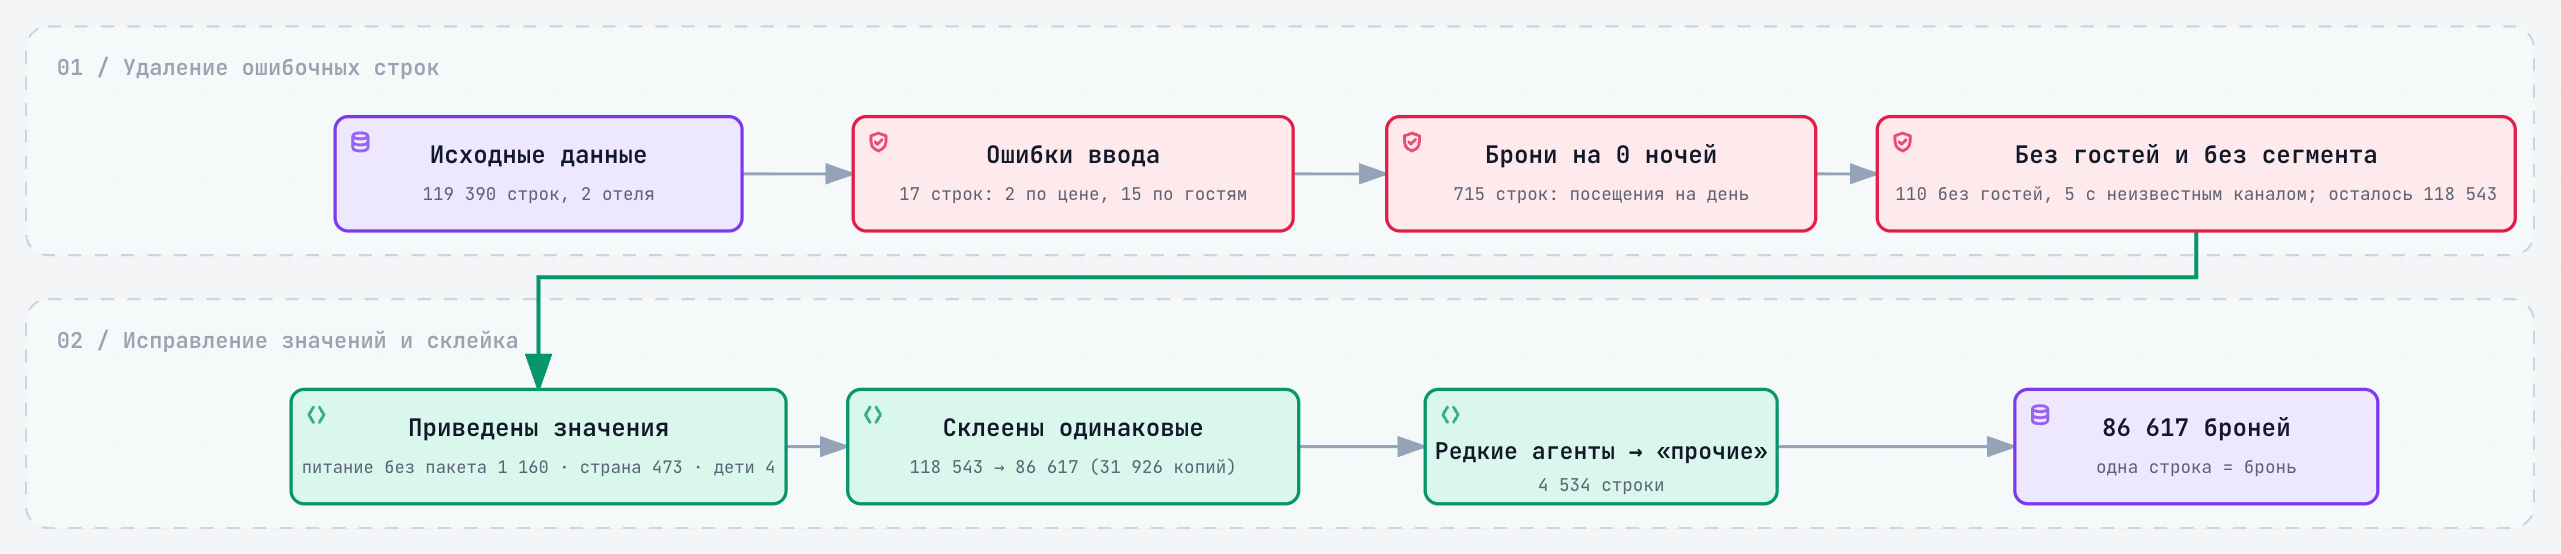

In [28]:
Image(filename=str(FIGURES_DIR / '24_cleaning_flow.png'))

На схеме два ряда. Сначала удаляются ошибочные строки: 17 ошибок ввода (цена и число гостей), 715 броней на 0 ночей, 110 броней без гостей и 5 с неизвестным каналом продаж; из 119 390 строк остаётся 118 543. Затем значения приводятся к единому виду (в 1 160 строках «питание не определено» заменено на «без пакета питания», в 473 пустая страна заменена на «неизвестно», в 4 заполнен пропуск в числе детей, удалена колонка номера недели). Одинаковые строки склеиваются в брони с числом номеров: 118 543 строки превращаются в 86 617 броней (31 926 строк были копиями). Склеиваем, а не удаляем, потому что такие копии — скорее номера одной групповой брони, а удаление занизило бы долю отмен. В конце редкие агенты (4 534 строки) объединяются в группу «прочие».

## 9. Выводы шага

1. **Что было не так.** В исходных 119 390 строках нашлись ошибки в цене (минус 6,38 € и 5 400 € за ночь при следующей по величине 510 €), нереальные брони на 20–55 взрослых, 715 броней на 0 ночей и 180 без гостей, значения `Undefined`, пропуски в стране, агенте, компании и числе детей, а также номер недели заезда, который не совпадает с датой у 53,7% броней. Кроме того, 31 994 строки полностью повторяют другие.
2. **Что удалили и почему.** Удалено 847 строк (0,7%): в основном 715 броней на 0 ночей (не проживание) и 110 броней без гостей, ещё 15 нереальных по числу гостей, 2 с ошибочной ценой и 5 с неопределённым сегментом или каналом. Это ошибки или не проживание, а объект исследования — номер, в котором собирались ночевать.
3. **Что изменили, не удаляя.** Пропущенные `children` заменены на 0 (4 брони), питание `Undefined` объединено с `SC` (1 160), пустая страна стала `unknown` (473), агенты с менее чем 100 бронями объединены в `other` (4 534 брони-решения), колонка с номером недели удалена. Нулевые цены оставлены с флагом `is_free` (1 040 броней), чтобы не терять реальные бесплатные и служебные брони.
4. **Решение по дублям.** Одинаковые строки сосредоточены в групповых продажах (75,1% копий в сегменте «Группы», 92,9% при депозите «без возврата») и встречаются группами до 10 и более строк, поэтому мы считаем их номерами одной групповой брони и склеиваем в одну бронь-решение с числом номеров `n_rooms` (вариант C): 31 926 строк склеены, осталось 118 543 номера и 86 617 броней-решений. Риск в том, что две независимые брони могли совпасть во всех колонках; из 3 160 подозрительных пар в индивидуальных продажах у 92,3% общий агент, так что случайное совпадение маловероятно.
5. **Проверка устойчивости.** Сравнение вариантов показало, что выбор важен: вариант A (удалить дубли) занижает долю отмен по номерам с 37,3% до 27,7% и долю отменённой стоимости бронирований с 39,2% до 33,3%. Вариант C даёт по номерам те же 37,3% и 39,2%, что и B, ничего не теряет, а по броням-решениям даёт 27,7%, потому что групповая отмена считается один раз.
6. **Гарантии.** Все 6 проверок выполнены: нет одинаковых строк, `n_rooms` не меньше 1, сумма `n_rooms` равна числу строк после удалений, ночи и гости не меньше 1, цена в допустимых пределах, нет `Undefined`, пропуски остались только в `agent`, `agent_id` и `company`, журнал очистки непрерывен. Это значит, что на дальнейших шагах можно не перепроверять базовую целостность данных.
7. **Что передаём дальше.** В шаг EDA и проверки гипотез идут очищенный датасет `data/processed/bookings_clean.parquet`, журнал `reports/cleaning_log.csv` и функция `compare_variants`, чтобы каждую гипотезу проверять на вариантах A, B и C.

**Ограничения.** В данных только два отеля в Португалии, поэтому выводы нельзя переносить на другие рынки.

В данных нет идентификатора брони, и то, что одинаковые строки — это номера одной групповой брони, остаётся обоснованным предположением, а не доказанным фактом. Поэтому на следующих шагах результаты проверяются на всех трёх вариантах обработки дублей.